<a href="https://colab.research.google.com/github/ignaciovelasco/Equipo1_IA/blob/main/Assignments/AF5_Convolutional_Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 5 — Convolutional Neural Network

**Team Number:** #1

**Class Schedule:** N3

**Team members:**

Ignacio Alberto Velasco García ID: 2177890

Dulce Aidé Vega del Angel ID: 2068193

Odalys Sherlyn Correa Galván ID: 2177754

Jonathan Sánchez Ramírez ID: 2111769

Gael Alejandro Reyes Zaragoza ID: 2178099



**1. Load libraries**

Import TensorFlow/Keras for the CNN, NumPy for array operations and Matplotlib to visualize images, training progress and predictions.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras import layers

# Reproducible random initialization.
tf.keras.utils.set_random_seed(42)
print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


**2. Load data**

Load MNIST using the required load_data() method. Keras provides the original split: 60,000 training images and 10,000 testing images. Each image is 28 × 28 pixels in grayscale, and each label is a digit from 0 to 9. No separate CSV or file upload is necessary.

In [ ]:
(train_data, train_labels), (test_data, test_label) = keras.datasets.mnist.load_data()

print("Training images:", train_data.shape)
print("Training labels:", train_labels.shape)
print("Testing images: ", test_data.shape)
print("Testing labels: ", test_label.shape)
print("Pixel range (before preprocessing):", train_data.min(), "to", train_data.max())


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images:  (10000, 28, 28)
Testing labels:  (10000,)
Pixel range (before preprocessing): 0 to 255


**3. Data preprocessing**

Normalize pixel values from 0–255 to 0–1 and add the grayscale channel dimension. The network needs each image to have shape (28, 28, 1). Keep integer labels 0–9, which are compatible with sparse categorical crossentropy. The original train/test split is preserved.

In [ ]:
# Normalize pixel values and add one channel for grayscale images.
train_data = np.expand_dims(train_data.astype("float32") / 255.0, axis=-1)
test_data = np.expand_dims(test_data.astype("float32") / 255.0, axis=-1)

print("Training data after preprocessing:", train_data.shape)
print("Testing data after preprocessing: ", test_data.shape)
print("Normalized pixel range:", train_data.min(), "to", train_data.max())
print("Classes:", np.unique(train_labels))


Training data after preprocessing: (60000, 28, 28, 1)
Testing data after preprocessing:  (10000, 28, 28, 1)
Normalized pixel range: 0.0 to 1.0
Classes: [0 1 2 3 4 5 6 7 8 9]


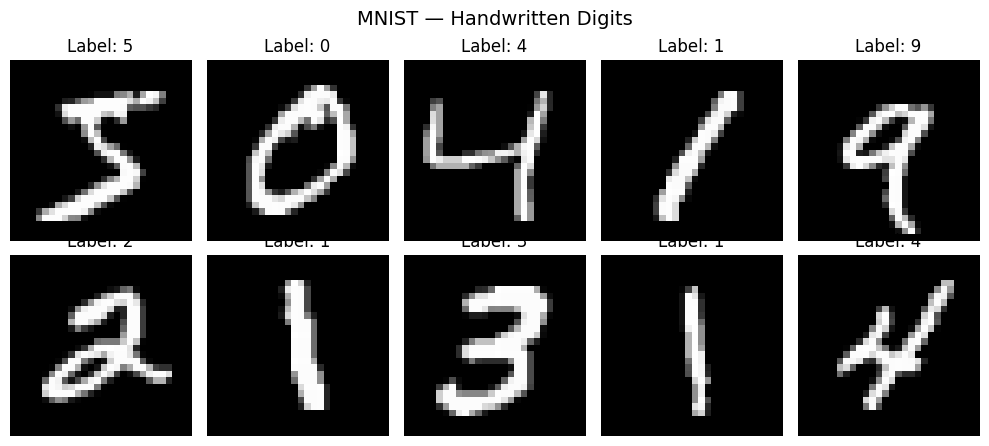

In [ ]:
# Display 10 examples from the training dataset.
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(train_data[i, :, :, 0], cmap="gray")
    ax.set_title(f"Label: {train_labels[i]}")
    ax.axis("off")
fig.suptitle("MNIST — Handwritten Digits", fontsize=14)
fig.tight_layout()
plt.show()


**4. Model selection and training**

CNN with two convolutional layers to detect image patterns, two max-pooling layers to reduce spatial dimensions, a flattening layer, and a dense feedforward classifier with softmax output for the ten digits.
- Output activation: softmax (10 probabilities)
- Loss: sparse_categorical_crossentropy (labels are integers 0–9)
- Optimizer: adam
- Training metric: accuracy
- Training method: model.fit() from Keras, using the training data only
- Validation: 10% of the training data; the 10,000 test images remain untouched until evaluation

In [ ]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
], name="MNIST_CNN")

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "MNIST_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_data,
    train_labels,
    epochs=3,
    batch_size=128,
    validation_split=0.10,
    verbose=2
)


Epoch 1/3
422/422 - 44s - 104ms/step - accuracy: 0.9281 - loss: 0.2489 - val_accuracy: 0.9813 - val_loss: 0.0644
Epoch 2/3
422/422 - 79s - 188ms/step - accuracy: 0.9792 - loss: 0.0676 - val_accuracy: 0.9868 - val_loss: 0.0482
Epoch 3/3
422/422 - 40s - 95ms/step - accuracy: 0.9848 - loss: 0.0479 - val_accuracy: 0.9883 - val_loss: 0.0402


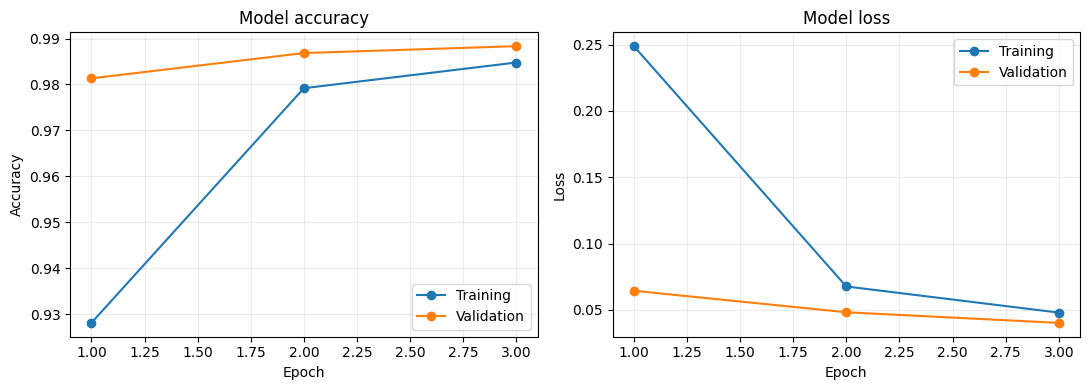

In [ ]:
# Training accuracy/loss plots (also useful as later evidence).
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
epochs = range(1, len(history.history["accuracy"]) + 1)

axes[0].plot(epochs, history.history["accuracy"], marker="o", label="Training")
axes[0].plot(epochs, history.history["val_accuracy"], marker="o", label="Validation")
axes[0].set_title("Model accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(epochs, history.history["loss"], marker="o", label="Training")
axes[1].plot(epochs, history.history["val_loss"], marker="o", label="Validation")
axes[1].set_title("Model loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.tight_layout()
fig.savefig("CNN_Training_History.png", dpi=160, bbox_inches="tight")
plt.show()


**5. Model testing**

Evaluate the trained model on the 10,000 original test images using the required Keras evaluate() method. Then perform exactly five predictions using test_data, showing the predicted digit and the real label side by side.

In [ ]:
test_loss, test_accuracy = model.evaluate(test_data, test_label, verbose=2)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")


313/313 - 3s - 8ms/step - accuracy: 0.9874 - loss: 0.0389
Test loss: 0.0389
Test accuracy: 0.9874 (98.74%)


Prediction 1: predicted = 7, actual = 7, correct = True
Prediction 2: predicted = 2, actual = 2, correct = True
Prediction 3: predicted = 1, actual = 1, correct = True
Prediction 4: predicted = 0, actual = 0, correct = True
Prediction 5: predicted = 4, actual = 4, correct = True


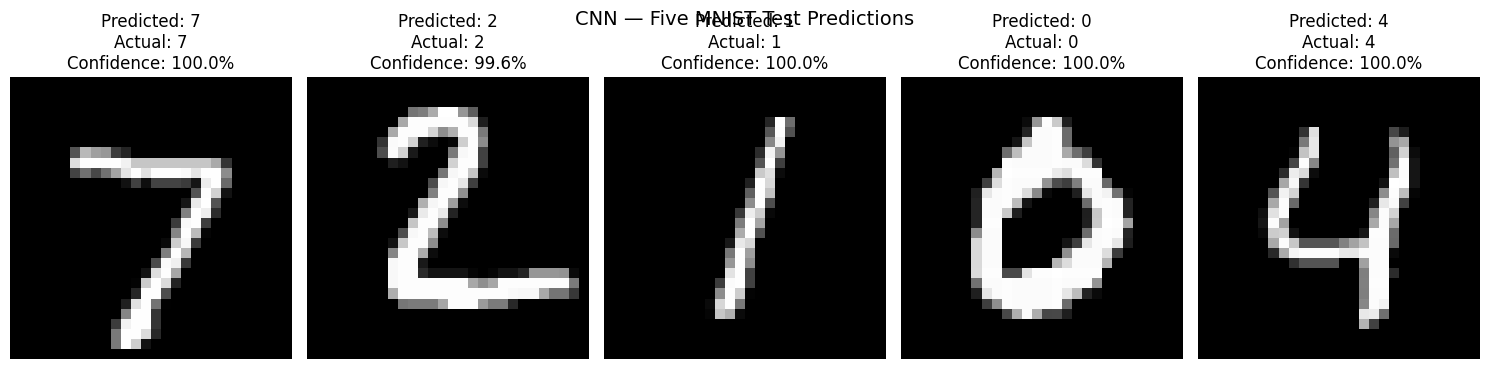

In [ ]:
# Five different predictions using the test dataset.
indices = [0, 1, 2, 3, 4]
probabilities = model.predict(test_data[indices], verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)

fig, axes = plt.subplots(1, 5, figsize=(15, 3.8))
for i, (idx, ax) in enumerate(zip(indices, axes)):
    actual = int(test_label[idx])
    predicted = int(predicted_labels[i])
    confidence = float(probabilities[i, predicted]) * 100

    ax.imshow(test_data[idx, :, :, 0], cmap="gray")
    ax.set_title(f"Predicted: {predicted}\nActual: {actual}\nConfidence: {confidence:.1f}%")
    ax.axis("off")
    print(f"Prediction {i + 1}: predicted = {predicted}, actual = {actual}, "
          f"correct = {predicted == actual}")

fig.suptitle("CNN — Five MNIST Test Predictions", fontsize=14)
fig.tight_layout()
fig.savefig("CNN_5_Predictions.png", dpi=160, bbox_inches="tight")
plt.show()
